In [3]:
import os, random, hashlib, zipfile, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# ---------------- global configuration ----------------
QUICK_RUN    = False            # True -> fewer folds/epochs (smoke test only, results will be worse)
IMG_SIZE     = (224, 224)       # input size expected by MobileNetV2 / ResNet50V2 / EfficientNetB0
BATCH        = 16
N_FOLDS      = 3  if QUICK_RUN else 5     # CV folds for the model comparison
CV_EPOCHS    = 8  if QUICK_RUN else 20    # epochs per CV run
FINAL_EPOCHS = 15 if QUICK_RUN else 40    # max epochs for final training (early stopping is on)
FT_EPOCHS    = 8  if QUICK_RUN else 20    # fine-tuning epochs
AUG_FOLDS    = 2  if QUICK_RUN else 3     # CV folds for the augmentation study (Task 3)
print("Config OK | QUICK_RUN =", QUICK_RUN)

Config OK | QUICK_RUN = False


In [4]:
ZIP_URL     = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"

In [5]:
import shutil, os
shutil.rmtree("rice_data", ignore_errors=True)
if os.path.exists("PRCP-1001-RiceLeaf.zip"):
    os.remove("PRCP-1001-RiceLeaf.zip")

In [ ]:
ZIP_URL     = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"
ZIP_PATH    = "PRCP-1001-RiceLeaf.zip"
EXTRACT_DIR = "rice_data"

if not os.path.exists(EXTRACT_DIR):
    if not os.path.exists(ZIP_PATH):
        import urllib.request
        print("Downloading dataset ...")
        urllib.request.urlretrieve(ZIP_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)
    print("Extracted to", EXTRACT_DIR)

IMG_EXT = (".jpg", ".jpeg", ".png")
rows = []
for root, _, files in os.walk(EXTRACT_DIR):
    if "__MACOSX" in root:
        continue
    for f in sorted(files):
        if f.lower().endswith(IMG_EXT) and not f.startswith("._"):
            rows.append({"path": os.path.join(root, f), "label": os.path.basename(root)})

df = pd.DataFrame(rows).sort_values(["label", "path"]).reset_index(drop=True)
print("Images found:", len(df))
print("Classes     :", df["label"].unique().tolist())
assert df["label"].nunique() == 3, "Expected 3 class folders - check the extracted folder structure"
display(df.head())

In [7]:
import os, collections
exts = collections.Counter()
for root, dirs, files in os.walk("rice_data"):
    print(root, "| subfolders:", dirs, "| files:", len(files), "| sample:", files[:3])
    for f in files:
        exts[os.path.splitext(f)[1].lower()] += 1
print("\nFile extensions found:", dict(exts))

rice_data | subfolders: ['classes', 'Data'] | files: 0 | sample: []
rice_data\classes | subfolders: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut'] | files: 0 | sample: []
rice_data\classes\Bacterial leaf blight | subfolders: ['Bacterial leaf blight'] | files: 0 | sample: []
rice_data\classes\Bacterial leaf blight\Bacterial leaf blight | subfolders: [] | files: 40 | sample: ['DSC_0365.JPG', 'DSC_0366.jpg', 'DSC_0367.JPG']
rice_data\classes\Brown spot | subfolders: ['Brown spot'] | files: 0 | sample: []
rice_data\classes\Brown spot\Brown spot | subfolders: [] | files: 40 | sample: ['DSC_0100.jpg', 'DSC_0101.jpg', 'DSC_0104.jpg']
rice_data\classes\Leaf smut | subfolders: ['Leaf smut'] | files: 0 | sample: []
rice_data\classes\Leaf smut\Leaf smut | subfolders: [] | files: 39 | sample: ['DSC_0293.JPG', 'DSC_0308.JPG', 'DSC_0309.JPG']
rice_data\Data | subfolders: [] | files: 3 | sample: ['Bacterial leaf blight-20200814T055237Z-001.zip', 'Brown spot-20200814T055208Z-001.zip', 'Leaf smut

In [ ]:
import re, shutil

EXTRACT_DIR = "rice_data"
IMG_EXT     = (".jpg", ".jpeg", ".png")

# 1) extract the inner zips (one per class), using the clean class name as the folder name
for root, _, files in os.walk(EXTRACT_DIR):
    for f in files:
        if f.lower().endswith(".zip"):
            class_name = re.sub(r"-\d{8}T\d+Z-\d+$", "", os.path.splitext(f)[0]).strip()
            out_dir = os.path.join(EXTRACT_DIR, "classes", class_name)
            if not os.path.exists(out_dir):
                with zipfile.ZipFile(os.path.join(root, f)) as z:
                    z.extractall(out_dir)
                print("Extracted:", f, "->", out_dir)

# 2) collect images; label = the class folder directly under rice_data/classes
CLASS_ROOT = os.path.join(EXTRACT_DIR, "classes")
rows = []
for root, _, files in os.walk(CLASS_ROOT):
    if "__MACOSX" in root:
        continue
    for f in sorted(files):
        if f.lower().endswith(IMG_EXT) and not f.startswith("._"):
            label = os.path.relpath(root, CLASS_ROOT).split(os.sep)[0]
            rows.append({"path": os.path.join(root, f), "label": label})

print("Images found:", len(rows))
assert rows, "Still 0 images - run the diagnostic cell on rice_data/classes and paste the output"

df = pd.DataFrame(rows).sort_values(["label", "path"]).reset_index(drop=True)
print("Classes     :", df["label"].unique().tolist())
print(df["label"].value_counts())
assert df["label"].nunique() == 3, "Expected 3 class folders - check the extracted folder structure"
display(df.head())

In [ ]:
Task1-complete data analysis report
1.1 class distribution(is the data balanced)

In [ ]:
counts = df["label"].value_counts().sort_index()
print(counts)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bars = ax[0].bar(counts.index, counts.values, color=sns.color_palette("viridis", len(counts)))
ax[0].bar_label(bars)
ax[0].set_title("Images per class"); ax[0].set_ylabel("count"); ax[0].tick_params(axis="x", rotation=15)
ax[1].pie(counts.values, labels=counts.index, autopct="%1.0f%%", startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()

imbalance_ratio = counts.max() / counts.min()
print(f"Imbalance ratio (max/min) = {imbalance_ratio:.2f}  ->", "balanced" if imbalance_ratio < 1.5 else "imbalanced")

In [ ]:
1.2-data quality:corrupt files,exact duplicates, near duplicates

In [10]:
bad = []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception as e:
        bad.append((p, str(e)))
print("Corrupt / unreadable images:", len(bad))

# --- exact duplicates
def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()
df["md5"] = df["path"].map(md5)
exact_dups = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("Images that are exact duplicates of another:", len(exact_dups))

# --- near duplicates (mean absolute pixel difference of 64x64 grey thumbnails)
from scipy.spatial.distance import cdist
def thumb(path, size=64):
    return cv2.resize(cv2.imread(path, cv2.IMREAD_GRAYSCALE), (size, size), interpolation=cv2.INTER_AREA).astype("float32").ravel()
T64 = np.stack([thumb(p) for p in df["path"]])
mad = cdist(T64, T64, "cityblock") / T64.shape[1]          # average grey-level difference (0-255 scale)
ii, jj = np.where(np.triu(mad < 1.0, k=1))
near_pairs = [(df.path[i], df.path[j], float(mad[i, j])) for i, j in zip(ii, jj)]
print("Near-duplicate pairs (average grey difference < 1 of 255):", len(near_pairs))
for a_, b_, d_ in near_pairs[:10]:
    print("  ", os.path.basename(a_), "<->", os.path.basename(b_), f"| mean abs diff {d_:.2f}")
if near_pairs:
    print("Open a few of these pairs and look at them: near-duplicates should be kept in the SAME split.")
if len(near_pairs) > 20:
    print("Very many hits -> probably images dominated by a plain background, not real duplicates; judge by eye.")

print("\nMissing values in table:\n", df[["path", "label"]].isna().sum())

Corrupt / unreadable images: 0
Images that are exact duplicates of another: 0
Near-duplicate pairs (average grey difference < 1 of 255): 0

Missing values in table:
 path     0
label    0
dtype: int64


In [ ]:
1.3-image dimensions,aspect ratio,file size

Colour modes: {'RGB': 119}


,width,height,aspect,megapixels,size_kb
count,119.00,119.00,119.00,119.00,119.00
mean,2383.64,707.74,3.33,2.03,307.77
std,1123.53,311.66,0.65,1.18,172.70
min,250.00,71.00,1.25,0.02,22.76
25%,1074.00,377.00,3.43,0.40,102.66
50%,3081.00,897.00,3.43,2.76,379.45
75%,3081.00,897.00,3.43,2.76,426.88
max,3081.00,900.00,5.30,2.76,643.40


width             height           aspect            \
                         mean   min   max   mean  min  max   mean  min  max   
label                                                                         
Bacterial leaf blight  3081.0  3081  3081  897.0  897  897    3.4  3.4  3.4   
Brown spot             1951.3   286  3081  589.2   88  900    3.3  1.3  5.3   
Leaf smut              2111.8   250  3081  635.2   71  897    3.3  1.2  5.0   

                      size_kb                
                         mean    min    max  
label                                        
Bacterial leaf blight   432.9  223.0  643.4  
Brown spot              240.2   22.8  509.9  
Leaf smut               248.7   23.7  437.0

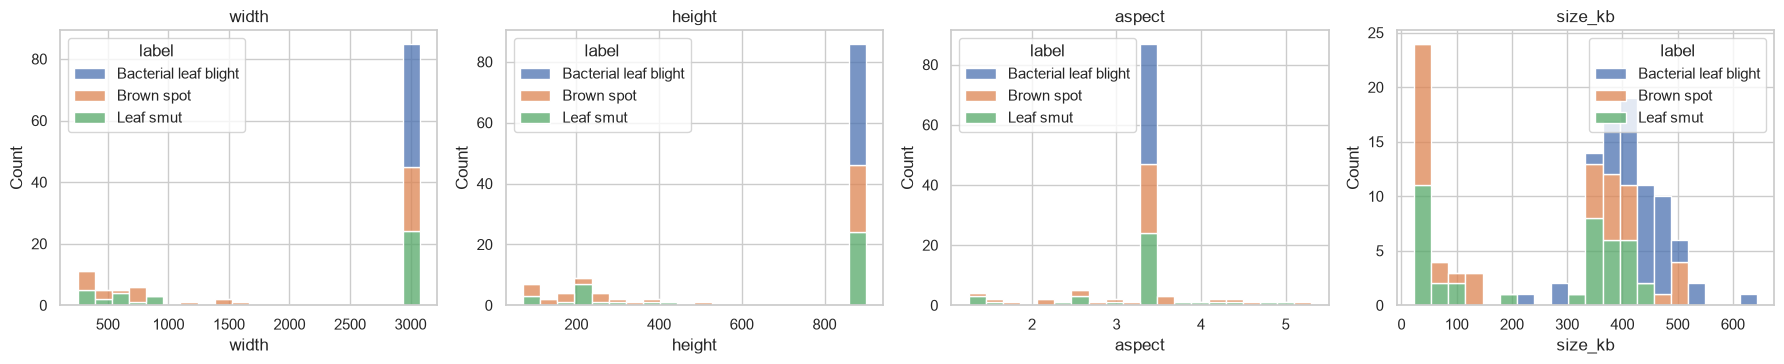

Unique image sizes: 34


In [11]:
def img_props(p):
    with Image.open(p) as im:
        return im.size[0], im.size[1], im.mode, os.path.getsize(p) / 1024
props = df["path"].apply(lambda p: pd.Series(img_props(p), index=["width", "height", "mode", "size_kb"]))
df = pd.concat([df.drop(columns=[c for c in props.columns if c in df.columns]), props], axis=1)
df["aspect"] = df["width"] / df["height"]
df["megapixels"] = df["width"] * df["height"] / 1e6

print("Colour modes:", df["mode"].value_counts().to_dict())
display(df[["width", "height", "aspect", "megapixels", "size_kb"]].describe().round(2))
display(df.groupby("label")[["width", "height", "aspect", "size_kb"]].agg(["mean", "min", "max"]).round(1))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, col in zip(ax, ["width", "height", "aspect", "size_kb"]):
    sns.histplot(data=df, x=col, hue="label", bins=20, multiple="stack", ax=a)
    a.set_title(col)
plt.tight_layout(); plt.show()

print("Unique image sizes:", df[["width", "height"]].drop_duplicates().shape[0])

In [ ]:
1.4-visual inspection-look at the data

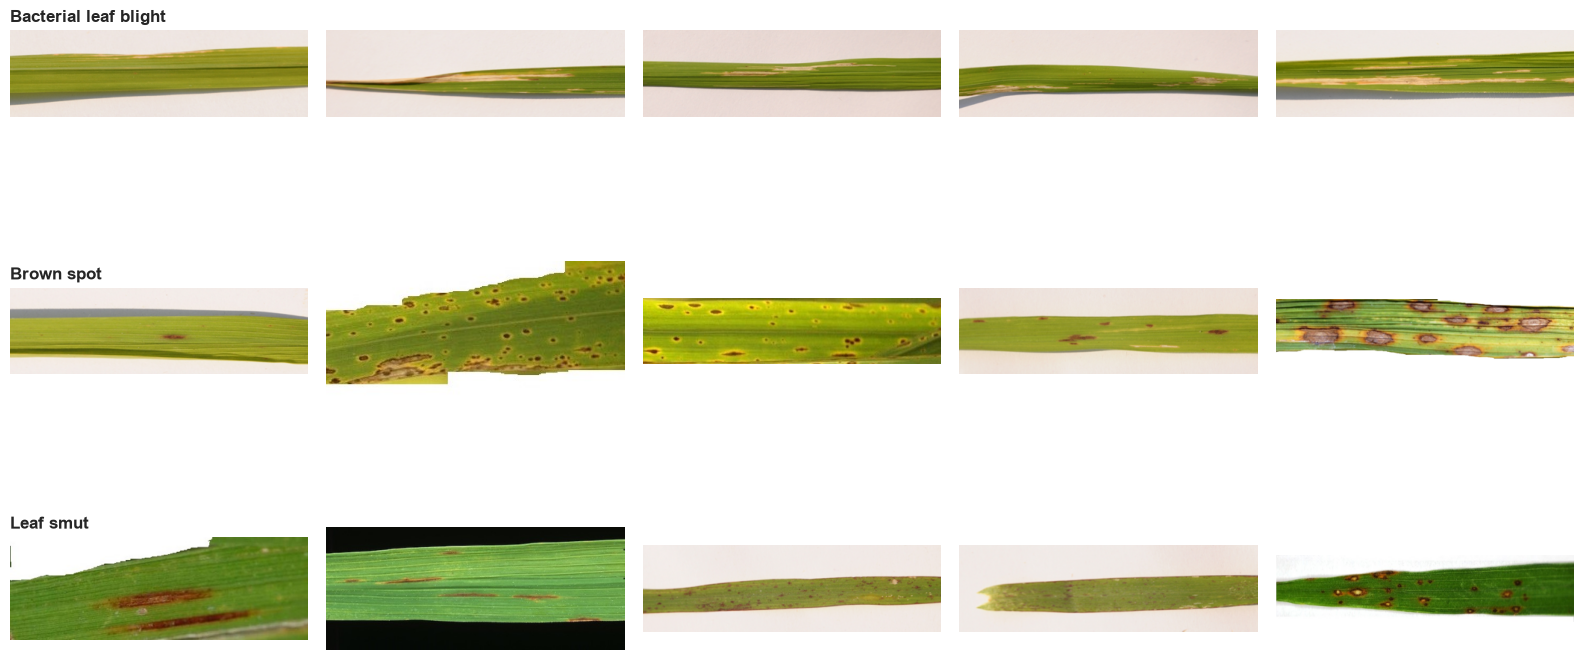

In [12]:
def show_samples(df, n=5, seed=SEED):
    classes = sorted(df["label"].unique())
    fig, axes = plt.subplots(len(classes), n, figsize=(3.2 * n, 3 * len(classes)))
    for r, cls in enumerate(classes):
        sub = df[df["label"] == cls].sample(n, random_state=seed)
        for c, p in enumerate(sub["path"]):
            im = Image.open(p).convert("RGB")
            im.thumbnail((400, 400))
            axes[r, c].imshow(im); axes[r, c].axis("off")
            if c == 0:
                axes[r, c].set_title(cls, loc="left", fontsize=12, fontweight="bold")
    plt.tight_layout(); plt.show()
show_samples(df)

In [ ]:
1.5-colour ,brightness, contrast and sharpness statistics

label,Bacterial leaf blight,Brown spot,Leaf smut
mean_r,194.20,191.27,180.11
mean_g,188.88,189.43,181.92
mean_b,152.22,126.64,141.41
brightness,186.30,182.83,176.76
contrast,55.16,49.77,55.10
sharpness,135.83,169.03,224.61
hue,18.55,22.03,22.68
sat,78.32,109.05,85.98
val,196.97,195.99,187.98
white_frac,0.28,0.30,0.36


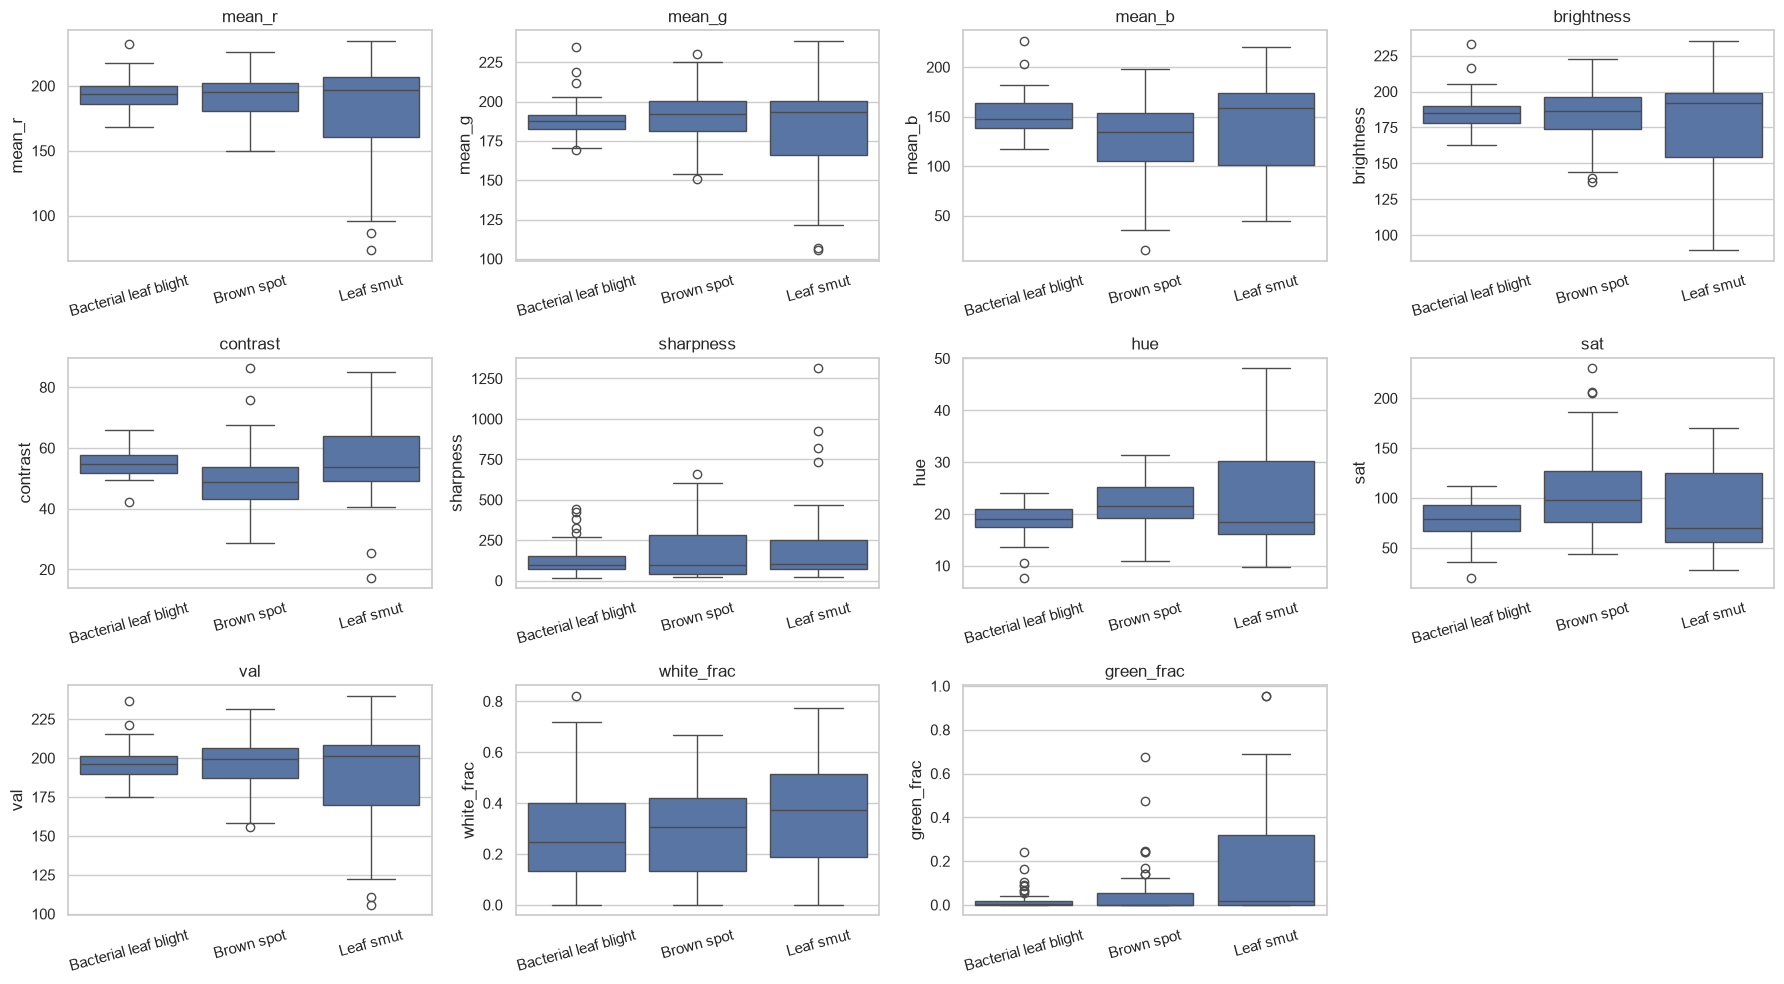

,feature,H_statistic,p_value,differs_between_classes (p<0.05)
4,contrast,14.44,0.000733,True
7,sat,10.46,0.005346,True
6,hue,7.93,0.018923,True
2,mean_b,7.11,0.028576,True
10,green_frac,5.88,0.052757,False
9,white_frac,3.03,0.219985,False
5,sharpness,1.27,0.529496,False
1,mean_g,1.18,0.553931,False
8,val,0.24,0.885756,False
3,brightness,0.08,0.961483,False


In [13]:
def quality_feats(p, size=256):
    rgb = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    s = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(s, cv2.COLOR_RGB2GRAY)
    hsv = cv2.cvtColor(s, cv2.COLOR_RGB2HSV)
    return dict(
        mean_r=s[..., 0].mean(), mean_g=s[..., 1].mean(), mean_b=s[..., 2].mean(),
        brightness=gray.mean(), contrast=gray.std(),
        sharpness=cv2.Laplacian(gray, cv2.CV_64F).var(),
        hue=hsv[..., 0].mean(), sat=hsv[..., 1].mean(), val=hsv[..., 2].mean(),
        white_frac=(s.min(axis=2) > 220).mean(),
        green_frac=((hsv[..., 0] > 35) & (hsv[..., 0] < 85) & (hsv[..., 1] > 40)).mean(),
    )

feat_cols = ["mean_r", "mean_g", "mean_b", "brightness", "contrast", "sharpness",
             "hue", "sat", "val", "white_frac", "green_frac"]
feat = pd.DataFrame([quality_feats(p) for p in df["path"]])
df = pd.concat([df.drop(columns=[c for c in feat_cols if c in df.columns]), feat], axis=1)

display(df.groupby("label")[feat_cols].mean().round(2).T)

fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.ravel(), feat_cols):
    sns.boxplot(data=df, x="label", y=col, ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
for ax in axes.ravel()[len(feat_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

from scipy.stats import kruskal
rows = []
for c in feat_cols:
    stat, pval = kruskal(*[g[c].values for _, g in df.groupby("label")])
    rows.append({"feature": c, "H_statistic": round(stat, 2), "p_value": pval, "differs_between_classes (p<0.05)": pval < 0.05})
kw = pd.DataFrame(rows).sort_values("p_value")
display(kw)

In [ ]:
1.6-colour histogram per class

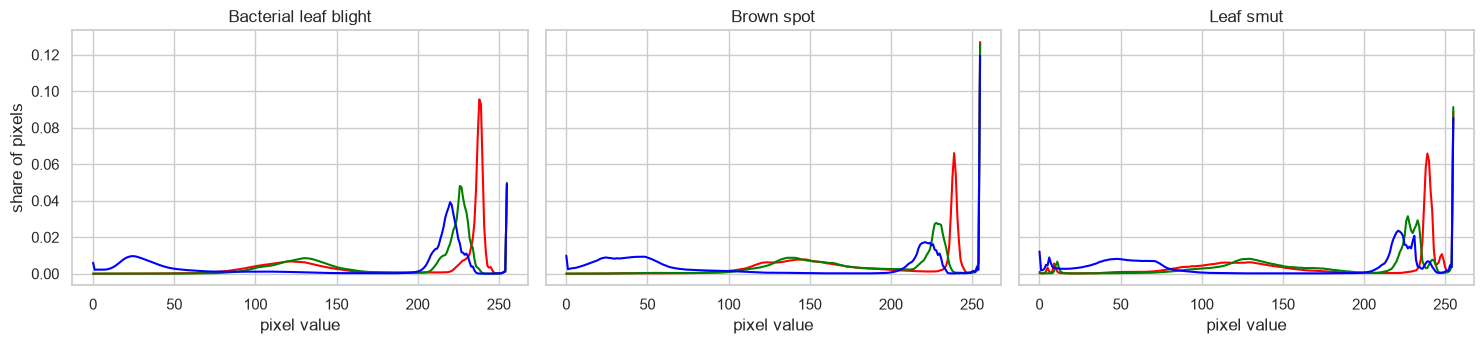

In [14]:
classes = sorted(df["label"].unique())
fig, axes = plt.subplots(1, len(classes), figsize=(5 * len(classes), 3.6), sharey=True)
for ax, cls in zip(np.atleast_1d(axes), classes):
    g = df[df["label"] == cls]
    acc = np.zeros((3, 256))
    for p in g["path"]:
        im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        for i in range(3):
            acc[i] += cv2.calcHist([im], [i], None, [256], [0, 256]).ravel() / (im.shape[0] * im.shape[1])
    acc /= len(g)
    for i, col in enumerate(["red", "green", "blue"]):
        ax.plot(acc[i], color=col)
    ax.set_title(cls); ax.set_xlabel("pixel value")
np.atleast_1d(axes)[0].set_ylabel("share of pixels")
plt.tight_layout(); plt.show()

In [ ]:
1.7- mean image  per class

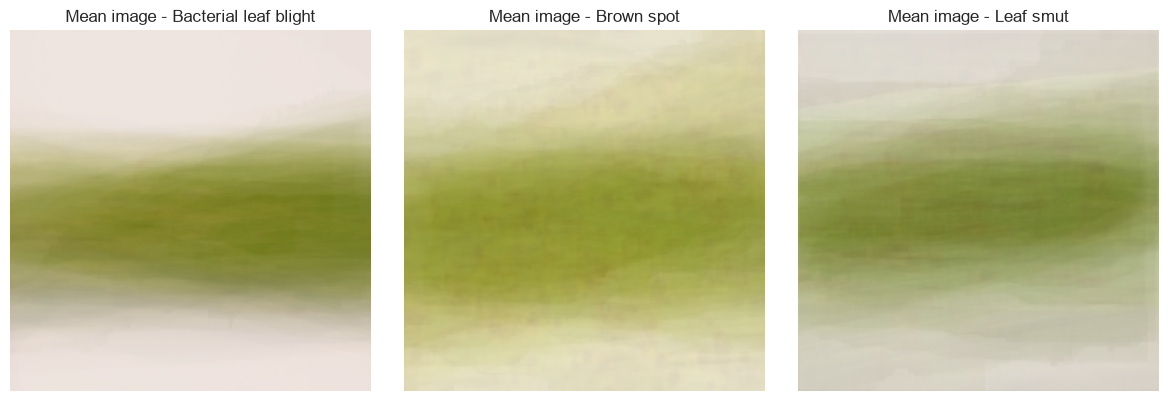

In [15]:
def mean_image(paths, size=(224, 224)):
    acc = np.zeros((size[1], size[0], 3), dtype="float64")
    for p in paths:
        acc += cv2.resize(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB), size, interpolation=cv2.INTER_AREA)
    return (acc / len(paths)).astype("uint8")

fig, axes = plt.subplots(1, len(classes), figsize=(4 * len(classes), 4))
for ax, cls in zip(np.atleast_1d(axes), classes):
    ax.imshow(mean_image(df.loc[df["label"] == cls, "path"])); ax.set_title(f"Mean image - {cls}"); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
1.8-clas separability:correlation,pca and t-sne

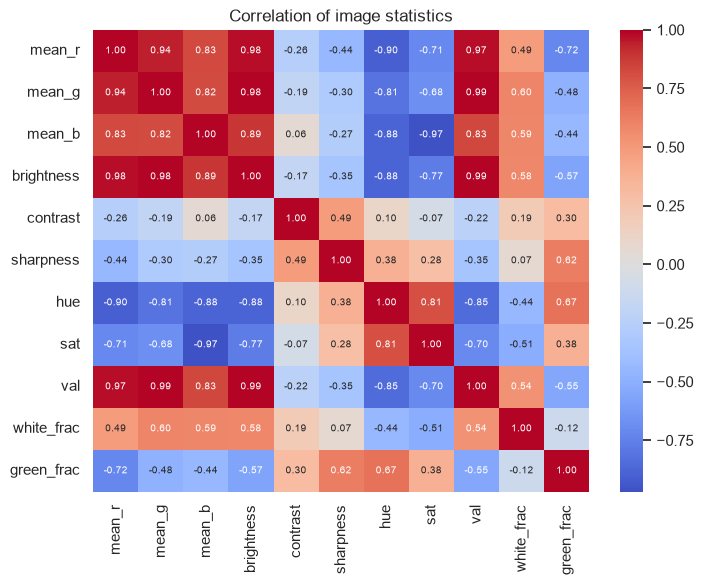

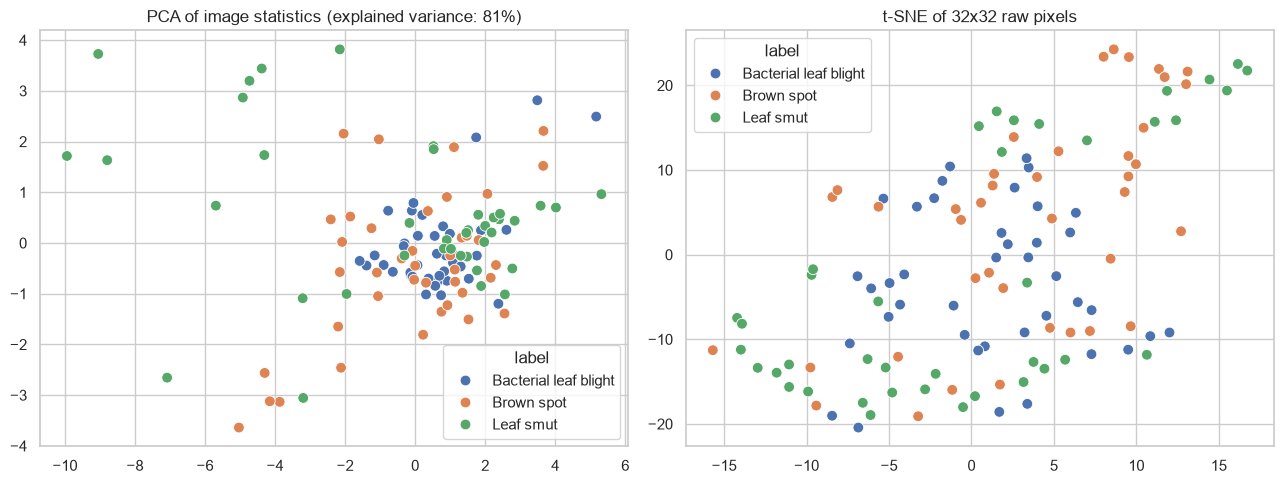

In [16]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

plt.figure(figsize=(8, 6))
sns.heatmap(df[feat_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation of image statistics"); plt.show()

Z = StandardScaler().fit_transform(df[feat_cols])
pca = PCA(2, random_state=SEED).fit(Z)
P = pca.transform(Z)

small = np.stack([cv2.resize(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB), (32, 32), interpolation=cv2.INTER_AREA).ravel()
                  for p in df["path"]]).astype("float32") / 255.0
T = TSNE(2, perplexity=15, random_state=SEED, init="pca").fit_transform(small)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df["label"], s=60, ax=ax[0])
ax[0].set_title(f"PCA of image statistics (explained variance: {pca.explained_variance_ratio_.sum():.0%})")
sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=df["label"], s=60, ax=ax[1])
ax[1].set_title("t-SNE of 32x32 raw pixels")
plt.tight_layout(); plt.show()

In [ ]:
1.9-Data analysis report(auto generated from the numbers above)

In [17]:
sig = kw[kw["differs_between_classes (p<0.05)"]]["feature"].tolist()
min_w, max_w = int(df["width"].min()), int(df["width"].max())
min_h, max_h = int(df["height"].min()), int(df["height"].max())
blurry = df.nlargest(1, "sharpness")["sharpness"].iloc[0], df.nsmallest(1, "sharpness")["sharpness"].iloc[0]

report_lines = [
    f"1. Size & balance: {len(df)} images, {df['label'].nunique()} classes, per-class counts = {counts.to_dict()} (imbalance ratio {imbalance_ratio:.2f}).",
    f"2. Quality: {len(bad)} corrupt files, {len(exact_dups)} exact-duplicate images, {len(near_pairs)} near-duplicate pairs, no missing labels.",
    f"3. Dimensions: widths {min_w}-{max_w}px, heights {min_h}-{max_h}px, aspect ratio {df['aspect'].min():.2f}-{df['aspect'].max():.2f}; "
    f"{df[['width','height']].drop_duplicates().shape[0]} distinct image sizes -> all images must be resized to {IMG_SIZE}.",
    f"4. Colour mode(s): {df['mode'].value_counts().to_dict()}.",
    f"5. Features that differ significantly between classes (Kruskal-Wallis, p<0.05): {sig if sig else 'none'}.",
    f"6. Sharpness (Laplacian variance) ranges from {blurry[1]:.0f} to {blurry[0]:.0f}; brightness {df['brightness'].min():.0f}-{df['brightness'].max():.0f} and contrast "
    f"{df['contrast'].min():.0f}-{df['contrast'].max():.0f} (0-255 scale) -> the wider these ranges, the more brightness/contrast augmentation is justified.",
    "7. Very small dataset (120 images): deep models trained from scratch will over-fit -> transfer learning, augmentation and cross-validation are required.",
]
print("\n".join(report_lines))

1. Size & balance: 119 images, 3 classes, per-class counts = {'Bacterial leaf blight': 40, 'Brown spot': 40, 'Leaf smut': 39} (imbalance ratio 1.03).
2. Quality: 0 corrupt files, 0 exact-duplicate images, 0 near-duplicate pairs, no missing labels.
3. Dimensions: widths 250-3081px, heights 71-900px, aspect ratio 1.25-5.30; 34 distinct image sizes -> all images must be resized to (224, 224).
4. Colour mode(s): {'RGB': 119}.
5. Features that differ significantly between classes (Kruskal-Wallis, p<0.05): ['contrast', 'sat', 'hue', 'mean_b'].
6. Sharpness (Laplacian variance) ranges from 19 to 1313; brightness 89-235 and contrast 17-86 (0-255 scale) -> the wider these ranges, the more brightness/contrast augmentation is justified.
7. Very small dataset (120 images): deep models trained from scratch will over-fit -> transfer learning, augmentation and cross-validation are required.


In [ ]:
Task2-model that classifies the three  rice-leaf diseases

In [14]:
import os, random, hashlib, zipfile, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# ---------------- global configuration ----------------
QUICK_RUN    = False            # True -> fewer folds/epochs (smoke test only, results will be worse)
IMG_SIZE     = (224, 224)       # input size expected by MobileNetV2 / ResNet50V2 / EfficientNetB0
BATCH        = 16
N_FOLDS      = 3  if QUICK_RUN else 5     # CV folds for the model comparison
CV_EPOCHS    = 8  if QUICK_RUN else 20    # epochs per CV run
FINAL_EPOCHS = 15 if QUICK_RUN else 40    # max epochs for final training (early stopping is on)
FT_EPOCHS    = 8  if QUICK_RUN else 20    # fine-tuning epochs
AUG_FOLDS    = 2  if QUICK_RUN else 3     # CV folds for the augmentation study (Task 3)
print("Config OK | QUICK_RUN =", QUICK_RUN)

Config OK | QUICK_RUN = False


In [15]:
ZIP_URL     = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"

In [25]:
import os, sys, time, random, warnings, pickle, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

SEED = 42
IMG_SIZE = 128
TEST_SIZE = 0.20
random.seed(SEED)
np.random.seed(SEED)
print("Setup done")

Setup done


In [36]:
idx_all = np.arange(len(images))
idx_train, idx_test = train_test_split(idx_all, test_size=TEST_SIZE,
                                       stratify=y, random_state=SEED)
imgs_train, imgs_test = images[idx_train], images[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

print("Train images:", len(idx_train), "| per class:", np.bincount(y_train))
print("Test  images:", len(idx_test),  "| per class:", np.bincount(y_test))

Train images: 95 | per class: [32 32 31]
Test  images: 24 | per class: [8 8 8]


In [37]:
import os, zipfile, shutil
from pathlib import Path
import numpy as np, cv2
from sklearn.preprocessing import LabelEncoder

ZIP_PATH = Path("PRCP-1001-RiceLeaf.zip")
OUT = Path("rice_data")
EXT = {".jpg", ".jpeg", ".png"}
IMG_SIZE = 128

shutil.rmtree(OUT, ignore_errors=True)
OUT.mkdir()

# 1) outer zip -> three inner zips
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(OUT / "_outer")

# 2) each inner zip -> folder named after the class (text before '-2020...')
for inner in sorted((OUT / "_outer").rglob("*.zip")):
    class_name = inner.stem.split("-2020")[0].strip()
    with zipfile.ZipFile(inner) as z:
        z.extractall(OUT / class_name)
    print("Extracted:", class_name)

# 3) find images; the label is the first folder under rice_data
image_paths = sorted(p for p in OUT.rglob("*")
                     if p.suffix.lower() in EXT and "_outer" not in p.parts
                     and "__MACOSX" not in p.parts and not p.name.startswith("._"))
print("Images found:", len(image_paths))
assert len(image_paths) > 0, "Still 0 images - tell me what folders are inside rice_data"

images, labels, orig_shapes = [], [], []
for p in image_paths:
    rgb = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    orig_shapes.append(rgb.shape[:2])
    images.append(cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
    labels.append(p.relative_to(OUT).parts[0])
images = np.array(images)
le = LabelEncoder(); y = le.fit_transform(labels)
class_names = list(le.classes_)
print(images.shape, class_names, np.bincount(y))

Extracted: Bacterial leaf blight
Extracted: Brown spot
Extracted: Leaf smut
Images found: 119
(119, 128, 128, 3) [np.str_('Bacterial leaf blight'), np.str_('Brown spot'), np.str_('Leaf smut')] [40 40 39]


In [38]:
for c in class_names:
    files = [p.name for p in (OUT / c).rglob("*") if p.is_file()]
    print(c, "| all files:", len(files), "| non-image files:", [f for f in files if Path(f).suffix.lower() not in EXT])

Bacterial leaf blight | all files: 40 | non-image files: []
Brown spot | all files: 40 | non-image files: []
Leaf smut | all files: 39 | non-image files: []


In [39]:
from collections import Counter
print(Counter(labels))                      # images per class found by the loader

folder = image_paths[0].parent.parent       # the folder that holds the class folders
print("Looking in:", folder.resolve())
for c in sorted(set(labels)):
    files = [p for p in folder.joinpath(c).rglob("*") if p.is_file()]
    others = [p.name for p in files if p.suffix.lower() not in {".jpg", ".jpeg", ".png"}]
    print(c, "| all files:", len(files), "| non-image files:", others)

Counter({'Bacterial leaf blight': 40, 'Brown spot': 40, 'Leaf smut': 39})
Looking in: C:\Users\rekul\rice_data\Bacterial leaf blight
Bacterial leaf blight | all files: 40 | non-image files: []
Brown spot | all files: 0 | non-image files: []
Leaf smut | all files: 0 | non-image files: []


In [40]:
   print(len(image_paths), images.shape, np.bincount(y))

119 (119, 128, 128, 3) [40 40 39]


In [41]:
idx_all = np.arange(len(images))
idx_train, idx_test = train_test_split(idx_all, test_size=TEST_SIZE,
                                       stratify=y, random_state=SEED)
imgs_train, imgs_test = images[idx_train], images[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

print("Train images:", len(idx_train), "| per class:", np.bincount(y_train))
print("Test  images:", len(idx_test),  "| per class:", np.bincount(y_test))

Train images: 95 | per class: [32 32 31]
Test  images: 24 | per class: [8 8 8]


In [48]:
def background_mask(img_rgb):
    """True where the pixel is leaf/foreground, False for near-white background."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    bg = (hsv[..., 1] < 35) & (hsv[..., 2] > 170)
    fg = ~bg
    if fg.mean() < 0.02:            # safety: never end up with an empty mask
        fg = np.ones_like(fg)
    return fg

def feature_parts(img_rgb, mask_bg=False):
    """Return an ordered dict {group_name: 1-D feature array} for one RGB uint8 image."""
    fg = background_mask(img_rgb) if mask_bg else np.ones(img_rgb.shape[:2], bool)
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m255 = fg.astype(np.uint8) * 255

    # 1) colour statistics (on foreground pixels)
    rgb_px, hsv_px = img_rgb[fg].astype(np.float32), hsv[fg].astype(np.float32)
    color_stats = np.concatenate([rgb_px.mean(0), rgb_px.std(0), hsv_px.mean(0), hsv_px.std(0)])

    # 2) HSV histograms (16 bins per channel, normalised)
    hists = []
    for ch, rng_ in zip(range(3), ([0, 180], [0, 256], [0, 256])):
        h = cv2.calcHist([hsv], [ch], m255, [16], rng_).ravel()
        hists.append(h / (h.sum() + 1e-9))
    hsv_hist = np.concatenate(hists)

    # 3) Local Binary Pattern histogram (10 'uniform' patterns)
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    lbp_hist = np.bincount(lbp[fg].astype(int), minlength=10).astype(np.float64)
    lbp_hist /= lbp_hist.sum() + 1e-9

    # For GLCM / HOG, blank out the background so it cannot influence texture/edges
    gray_m = gray * fg
    # 4) GLCM texture (32 grey levels, distances 1 and 3, angles 0 and 90 deg)
    glcm = graycomatrix((gray_m // 8).astype(np.uint8), distances=[1, 3],
                        angles=[0, np.pi / 2], levels=32, symmetric=True, normed=True)
    glcm_feat = np.concatenate([graycoprops(glcm, p).mean(axis=1)
                                for p in ("contrast", "homogeneity", "energy", "correlation")])

    # 5) HOG
    hog_feat = hog(gray_m, orientations=9, pixels_per_cell=(32, 32),
                   cells_per_block=(2, 2), block_norm="L2-Hys")

    return {"color_stats": color_stats, "hsv_hist": hsv_hist, "lbp": lbp_hist,
            "glcm": glcm_feat, "hog": hog_feat}

def extract_features(img_rgb, mask_bg=False):
    return np.concatenate(list(feature_parts(img_rgb, mask_bg).values()))

# size of each feature group and where it sits inside the full vector
_sample = feature_parts(images[0])
GROUP_SIZES = {k: len(v) for k, v in _sample.items()}
bounds = np.cumsum([0] + list(GROUP_SIZES.values()))
GROUP_SLICES = {k: np.arange(bounds[i], bounds[i + 1]) for i, k in enumerate(GROUP_SIZES)}
print("Feature groups and sizes:", GROUP_SIZES)
print("Total features per image:", sum(GROUP_SIZES.values()))

Feature groups and sizes: {'color_stats': 12, 'hsv_hist': 48, 'lbp': 10, 'glcm': 8, 'hog': 324}
Total features per image: 402


In [49]:
t0 = time.time()
X_all = np.array([extract_features(im) for im in images])
total_t = time.time() - t0
FEATURE_MS = 1000 * total_t / len(images)

X_train, X_test = X_all[idx_train], X_all[idx_test]
print("Feature matrix shape :", X_all.shape)
print(f"Extraction time      : {total_t:.1f} s total = {FEATURE_MS:.1f} ms per image")
print("NaN values           :", int(np.isnan(X_all).sum()))

Feature matrix shape : (119, 402)
Extraction time      : 2.4 s total = 20.3 ms per image
NaN values           : 0


In [56]:
def stratified_subsample(idx, y_, frac, rng):
    if frac >= 1.0:
        return idx
    keep = []
    for c in np.unique(y_[idx]):
        ci = idx[y_[idx] == c]
        n = max(2, int(round(frac * len(ci))))
        keep.extend(rng.choice(ci, n, replace=False))
    return np.array(sorted(keep))

def cv_evaluate(model, X, y_, aug=None, cols=None, n_splits=5, n_repeats=2,
                train_frac=1.0, seed=SEED):
    """Repeated stratified CV. `aug` has shape (n_images, k, n_features)."""
    if cols is not None:
        X = X[:, cols]
        aug = aug[..., cols] if aug is not None else None
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    rng = np.random.default_rng(seed)
    accs, f1s = [], []
    for tr, va in rskf.split(X, y_):
        tr = stratified_subsample(tr, y_, train_frac, rng)
        Xtr, ytr = X[tr], y_[tr]
        if aug is not None:
            A = aug[tr]; k = A.shape[1]
            Xtr = np.vstack([Xtr, A.reshape(-1, A.shape[-1])])
            ytr = np.concatenate([ytr, np.repeat(y_[tr], k)])
        m = clone(model).fit(Xtr, ytr)
        pred = m.predict(X[va])
        accs.append(accuracy_score(y_[va], pred))
        f1s.append(f1_score(y_[va], pred, average="macro"))
    return np.array(accs), np.array(f1s)

In [57]:
def make_models():
    sc = lambda: StandardScaler()
    return {
        "Logistic Regression":    Pipeline([("sc", sc()), ("clf", LogisticRegression(max_iter=3000, random_state=SEED))]),
        "KNN":                    Pipeline([("sc", sc()), ("clf", KNeighborsClassifier(n_neighbors=5))]),
        "SVM (RBF)":              Pipeline([("sc", sc()), ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED))]),
        "SVM (Linear)":           Pipeline([("sc", sc()), ("clf", SVC(kernel="linear", C=1.0, random_state=SEED))]),
        "Random Forest":          Pipeline([("sc", sc()), ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
        "Extra Trees":            Pipeline([("sc", sc()), ("clf", ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
        "Gradient Boosting":      Pipeline([("sc", sc()), ("clf", HistGradientBoostingClassifier(max_iter=100, random_state=SEED))]),
        "Gaussian Naive Bayes":   Pipeline([("sc", sc()), ("clf", GaussianNB())]),
        "MLP (Neural Net)":       Pipeline([("sc", sc()), ("clf", MLPClassifier(hidden_layer_sizes=(128,), max_iter=800, random_state=SEED))]),
    }

models = make_models()
rows = []
for name, mdl in models.items():
    t0 = time.time()
    acc, f1 = cv_evaluate(mdl, X_train, y_train)
    rows.append({"Model": name, "CV accuracy": acc.mean(), "± std": acc.std(),
                 "CV macro-F1": f1.mean(), "Time (s)": time.time() - t0})
baseline_df = pd.DataFrame(rows).sort_values("CV accuracy", ascending=False).reset_index(drop=True)
display(baseline_df.round(4))

,Model,CV accuracy,± std,CV macro-F1,Time (s)
0,Extra Trees,0.7211,0.0746,0.7187,13.2932
1,MLP (Neural Net),0.7158,0.1228,0.7104,2.9328
2,Random Forest,0.7053,0.0714,0.7000,16.1181
3,SVM (Linear),0.7053,0.0918,0.7012,0.1048
4,Gradient Boosting,0.6947,0.1021,0.6919,23.7469
5,Logistic Regression,0.6737,0.1073,0.6712,0.8237
6,SVM (RBF),0.6526,0.0976,0.6468,0.1499
7,KNN,0.6474,0.0817,0.6420,0.4844
8,Gaussian Naive Bayes,0.5526,0.1206,0.5349,0.1131


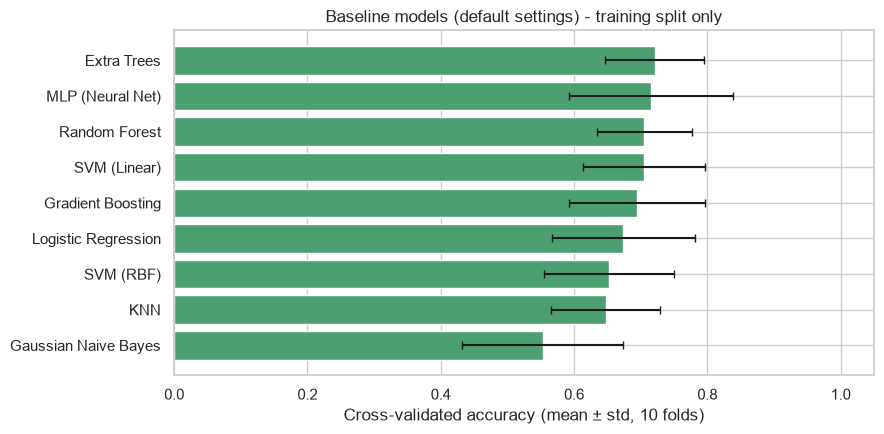

Best baseline: Extra Trees with CV accuracy 0.721 (± 0.075). Chance level for 3 balanced classes is 0.333.


In [58]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(baseline_df["Model"][::-1], baseline_df["CV accuracy"][::-1],
        xerr=baseline_df["± std"][::-1], color="#4c9f70", capsize=3)
ax.set_xlabel("Cross-validated accuracy (mean ± std, 10 folds)")
ax.set_title("Baseline models (default settings) - training split only")
ax.set_xlim(0, 1.05); plt.tight_layout(); plt.show()

best_base = baseline_df.iloc[0]
print(f"Best baseline: {best_base['Model']} with CV accuracy {best_base['CV accuracy']:.3f} "
      f"(± {best_base['± std']:.3f}). Chance level for 3 balanced classes is 0.333.")

In [59]:
param_grids = {
    "SVM (RBF)":           {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 1e-3, 1e-2]},
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10, 100]},
    "KNN":                 {"clf__n_neighbors": [1, 3, 5, 7], "clf__weights": ["uniform", "distance"]},
    "Random Forest":       {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 10],
                            "clf__max_features": ["sqrt", "log2"]},
}
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tuned, tune_rows = {}, []
for name, grid in param_grids.items():
    t0 = time.time()
    gs = GridSearchCV(models[name], grid, cv=inner_cv, scoring="accuracy", n_jobs=1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    tune_rows.append({"Model": name, "Best params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                      "Grid-search CV acc": gs.best_score_, "Time (s)": time.time() - t0})
tune_df = pd.DataFrame(tune_rows)
pd.set_option("display.max_colwidth", 120)
display(tune_df.round(4))

,Model,Best params,Grid-search CV acc,Time (s)
0,SVM (RBF),"{'C': 10, 'gamma': 'scale'}",0.7368,0.7395
1,Logistic Regression,{'C': 100},0.7474,0.9411
2,KNN,"{'n_neighbors': 1, 'weights': 'uniform'}",0.7263,0.7236
3,Random Forest,"{'max_depth': None, 'max_features': 'log2', 'n_estimators': 400}",0.8105,46.4933


In [60]:
final_models = {**models, **tuned}          # tuned versions replace the defaults
rows = []
for name, mdl in final_models.items():
    acc, f1 = cv_evaluate(mdl, X_train, y_train, seed=SEED + 1)   # different splits than the grid search
    rows.append({"Model": name, "Tuned?": name in tuned, "CV accuracy": acc.mean(),
                 "± std": acc.std(), "CV macro-F1": f1.mean()})
select_df = pd.DataFrame(rows).sort_values(["CV accuracy", "± std"], ascending=[False, True]).reset_index(drop=True)
display(select_df.round(4))

best_name = select_df.iloc[0]["Model"]
print("\nSelected model for Task 2:", best_name)
if best_name in tuned:
    print("Settings:", {k: v for k, v in tuned[best_name].named_steps["clf"].get_params().items()
                        if k in ("C", "gamma", "n_neighbors", "weights", "n_estimators", "max_depth", "max_features")})

,Model,Tuned?,CV accuracy,± std,CV macro-F1
0,Extra Trees,False,0.7684,0.0887,0.7642
1,MLP (Neural Net),False,0.7632,0.1059,0.7491
2,Logistic Regression,True,0.7579,0.0714,0.7512
3,Random Forest,True,0.7421,0.1187,0.7357
4,SVM (Linear),False,0.7368,0.1026,0.7296
5,SVM (RBF),True,0.7316,0.0684,0.7177
6,KNN,True,0.7263,0.0906,0.7248
7,Gradient Boosting,False,0.7263,0.1408,0.7256
8,Gaussian Naive Bayes,False,0.5737,0.0761,0.5628



Selected model for Task 2: Extra Trees


TEST accuracy : 0.8333  (20 of 24 correct)
TEST macro-F1 : 0.8356

                       precision    recall  f1-score   support

Bacterial leaf blight      0.778     0.875     0.824         8
           Brown spot      0.750     0.750     0.750         8
            Leaf smut      1.000     0.875     0.933         8

             accuracy                          0.833        24
            macro avg      0.843     0.833     0.836        24
         weighted avg      0.843     0.833     0.836        24



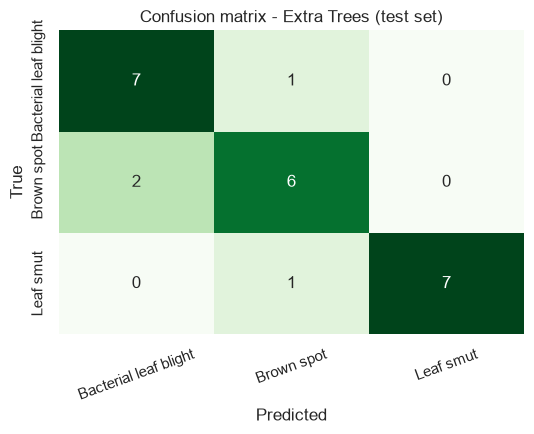

In [61]:
final_model = clone(final_models[best_name]).fit(X_train, y_train)
test_pred = final_model.predict(X_test)
test_acc = accuracy_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred, average="macro")

print(f"TEST accuracy : {test_acc:.4f}  ({int(round(test_acc*len(y_test)))} of {len(y_test)} correct)")
print(f"TEST macro-F1 : {test_f1:.4f}\n")
print(classification_report(y_test, test_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax,
            xticklabels=class_names, yticklabels=class_names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Confusion matrix - {best_name} (test set)")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

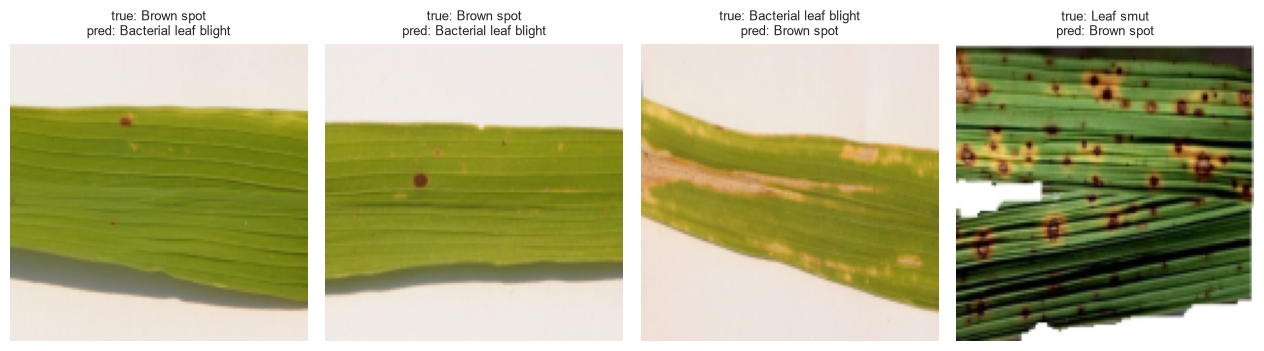

4 misclassified image(s) out of 24.


In [64]:
wrong = np.where(test_pred != y_test)[0]
if len(wrong) == 0:
    print("No misclassified test images - the model got all", len(y_test), "right.")
else:
    n = len(wrong)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.6), squeeze=False)
    for ax, i in zip(axes[0], wrong):
        ax.imshow(imgs_test[i]); ax.axis("off")
        ax.set_title(f"true: {class_names[y_test[i]]}\npred: {class_names[test_pred[i]]}", fontsize=9)
    plt.tight_layout(); plt.show()
    print(f"{n} misclassified image(s) out of {len(y_test)}.")


In [65]:
print("TASK 2 SUMMARY")
print("-" * 60)
print(f"* Data           : {len(images)} images, {len(class_names)} classes, resized to {IMG_SIZE}x{IMG_SIZE}")
print(f"* Split          : {len(idx_train)} train / {len(idx_test)} test (stratified)")
print(f"* Features       : {X_all.shape[1]} per image (colour, HSV histogram, LBP, GLCM, HOG)")
print(f"* Models tried   : {len(final_models)}")
print(f"* Selected model : {best_name}  (CV accuracy {select_df.iloc[0]['CV accuracy']:.3f} ± {select_df.iloc[0]['± std']:.3f})")
print(f"* Test accuracy  : {test_acc:.3f}   macro-F1: {test_f1:.3f}")

TASK 2 SUMMARY
------------------------------------------------------------
* Data           : 119 images, 3 classes, resized to 128x128
* Split          : 95 train / 24 test (stratified)
* Features       : 402 per image (colour, HSV histogram, LBP, GLCM, HOG)
* Models tried   : 9
* Selected model : Extra Trees  (CV accuracy 0.768 ± 0.089)
* Test accuracy  : 0.833   macro-F1: 0.836


In [ ]:
Task3- Analyse data-agumentation and other techniques

In [67]:
def aug_geometric(img, rng):
    h, w = img.shape[:2]
    out = img
    if rng.random() < 0.5: out = cv2.flip(out, 1)          # horizontal flip
    if rng.random() < 0.5: out = cv2.flip(out, 0)          # vertical flip
    angle = rng.uniform(-45, 45)
    scale = rng.uniform(0.85, 1.15)
    tx, ty = rng.uniform(-0.08, 0.08, 2) * w
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    M[:, 2] += (tx, ty)
    return cv2.warpAffine(out, M, (w, h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REFLECT_101)

def aug_photometric(img, rng):
    out = img.astype(np.float32) / 255.0
    out = out ** rng.uniform(0.8, 1.25)                              # gamma
    out = (out - 0.5) * rng.uniform(0.85, 1.15) + 0.5 + rng.uniform(-0.08, 0.08)  # contrast + brightness
    if rng.random() < 0.5:
        out = out + rng.normal(0, rng.uniform(0.01, 0.03), out.shape)  # Gaussian noise
    out = (np.clip(out, 0, 1) * 255).astype(np.uint8)
    if rng.random() < 0.3:
        out = cv2.GaussianBlur(out, (3, 3), 0)                         # slight blur
    return out

def aug_combined(img, rng):
    return aug_photometric(aug_geometric(img, rng), rng)

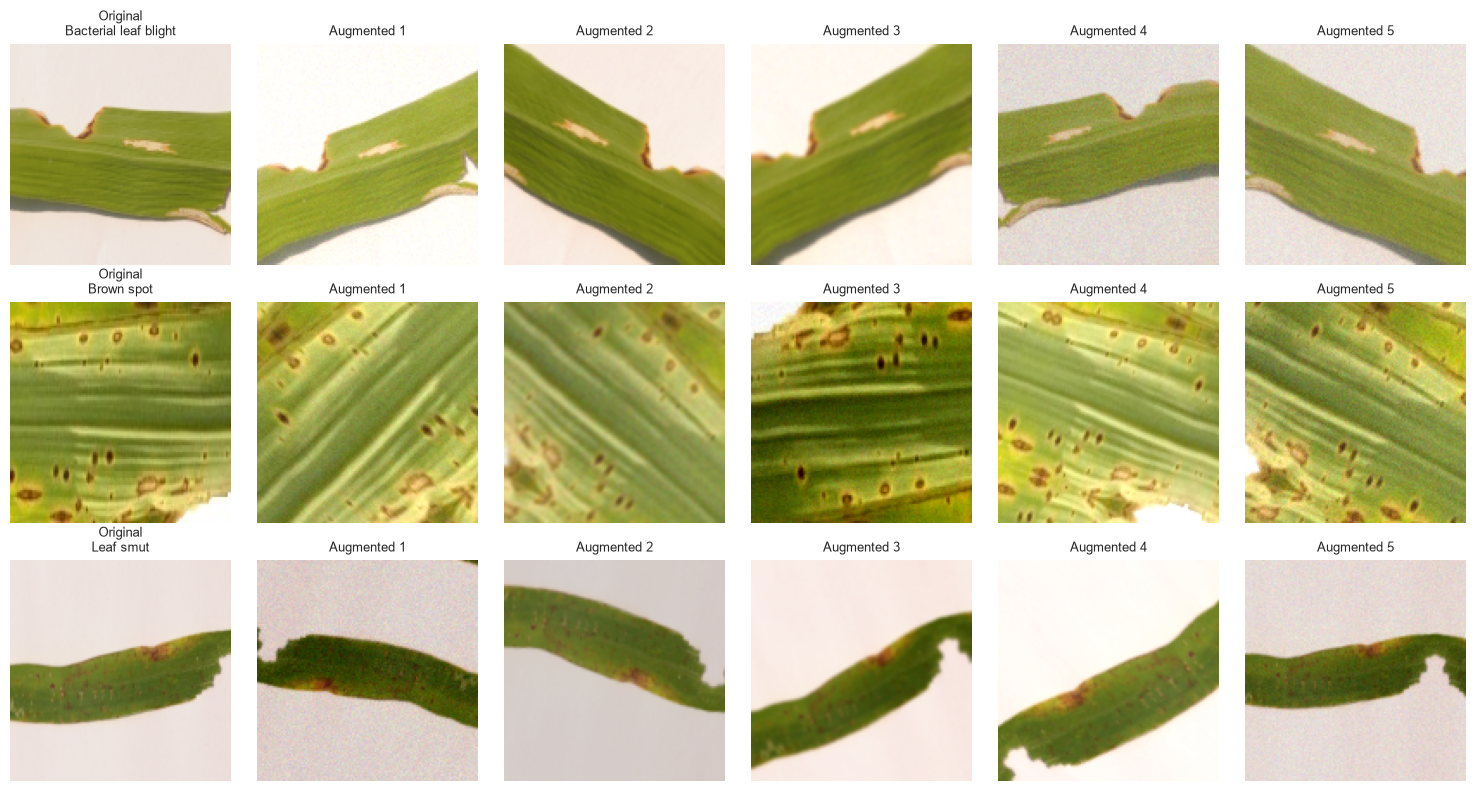

In [68]:
rng_demo = np.random.default_rng(7)
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for r, c in enumerate(range(3)):
    src = imgs_train[np.where(y_train == c)[0][0]]
    axes[r, 0].imshow(src); axes[r, 0].set_title(f"Original\n{class_names[c]}", fontsize=9)
    for j in range(1, 6):
        axes[r, j].imshow(aug_combined(src, rng_demo)); axes[r, j].set_title(f"Augmented {j}", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

In [73]:
src = imgs_train[0]
rng_one = np.random.default_rng(3)
singles = {
    "Original": src,
    "Horizontal flip": cv2.flip(src, 1),
    "Vertical flip": cv2.flip(src, 0),
    "Rotate 30°": cv2.warpAffine(src, cv2.getRotationMatrix2D((IMG_SIZE/2, IMG_SIZE/2), 30, 1.0), (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT_101),
    "Zoom in 1.25x": cv2.warpAffine(src, cv2.getRotationMatrix2D((IMG_SIZE/2, IMG_SIZE/2), 0, 1.25), (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT_101),
    "Brighter": cv2.convertScaleAbs(src, alpha=1.0, beta=30),
    "Darker": cv2.convertScaleAbs(src, alpha=1.0, beta=-30),
    "Gaussian noise": np.clip(src + rng_one.normal(0, 10, src.shape), 0, 255).astype(np.uint8),
    "Blur": cv2.GaussianBlur(src, (5, 5), 0),
}
src = imgs_train[0]
rng_one = np.random.default_rng(3)
singles = {
    "Original": src,
    "Horizontal flip": cv2.flip(src, 1),
    "Vertical flip": cv2.flip(src, 0),
    "Rotate 30°": cv2.warpAffine(src, cv2.getRotationMatrix2D((IMG_SIZE/2, IMG_SIZE/2), 30, 1.0), (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT_101),
    "Zoom in 1.25x": cv2.warpAffine(src, cv2.getRotationMatrix2D((IMG_SIZE/2, IMG_SIZE/2), 0, 1.25), (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT_101),
    "Brighter": cv2.convertScaleAbs(src, alpha=1.0, beta=30),
    "Darker": cv2.convertScaleAbs(src, alpha=1.0, beta=-30),
    "Gaussian noise": np.clip(src + rng_one.normal(0, 10, src.shape), 0, 255).astype(np.uint8),
    "Blur": cv2.GaussianBlur(src, (5, 5), 0),
}

In [74]:
K_AUG = 8

def build_aug_pool(imgs, aug_fn, k=K_AUG, base_seed=SEED):
    pool = np.zeros((len(imgs), k, X_all.shape[1]), dtype=np.float64)
    for i, im in enumerate(imgs):
        rng = np.random.default_rng(base_seed * 1000 + i)
        for j in range(k):
            pool[i, j] = extract_features(aug_fn(im, rng))
    return pool

t0 = time.time()
pool_geo   = build_aug_pool(imgs_train, aug_geometric)
pool_photo = build_aug_pool(imgs_train, aug_photometric)
pool_combo = build_aug_pool(imgs_train, aug_combined)
print(f"Built 3 pools of shape {pool_combo.shape} in {time.time() - t0:.0f} s")
print(f"Each pool adds {pool_combo.shape[0] * pool_combo.shape[1]} synthetic samples to the {len(idx_train)} real training images.")

Built 3 pools of shape (95, 8, 402) in 66 s
Each pool adds 760 synthetic samples to the 95 real training images.


In [75]:
AUG_CONFIGS = {
    "No augmentation": None,
    "Geometric x8": pool_geo,
    "Photometric x8": pool_photo,
    "Geo+Photo x8": pool_combo,
}
exp_models = {n: tuned[n] for n in ("SVM (RBF)", "Logistic Regression", "Random Forest")}

rows = []
for mname, mdl in exp_models.items():
    for aname, pool in AUG_CONFIGS.items():
        acc, f1 = cv_evaluate(mdl, X_train, y_train, aug=pool)
        rows.append({"Model": mname, "Augmentation": aname, "mean": acc.mean(), "std": acc.std(), "f1": f1.mean()})
augA = pd.DataFrame(rows)
tabA = augA.pivot(index="Model", columns="Augmentation", values="mean")[list(AUG_CONFIGS)]
print("Mean CV accuracy:")
display(tabA.round(4))

Mean CV accuracy:


Augmentation,No augmentation,Geometric x8,Photometric x8,Geo+Photo x8
Model,,,,
Logistic Regression,0.7105,0.7263,0.6316,0.7158
Random Forest,0.7211,0.8474,0.7000,0.8000
SVM (RBF),0.6947,0.7579,0.6895,0.7737


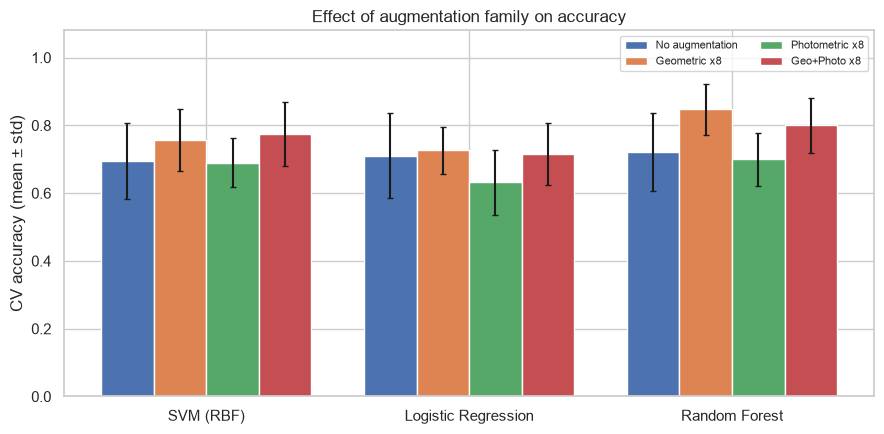

Average accuracy over the 3 models:
Augmentation
No augmentation    0.7088
Geometric x8       0.7772
Photometric x8     0.6737
Geo+Photo x8       0.7632

Best setting: Geometric x8  (0.777 vs 0.709 without augmentation, change = +6.8 percentage points)


In [72]:
fig, ax = plt.subplots(figsize=(9, 4.5))
w = 0.2
for j, aname in enumerate(AUG_CONFIGS):
    sub = augA[augA["Augmentation"] == aname].set_index("Model").loc[list(exp_models)]
    ax.bar(np.arange(len(exp_models)) + (j - 1.5) * w, sub["mean"], w, yerr=sub["std"], capsize=2, label=aname)
ax.set_xticks(np.arange(len(exp_models))); ax.set_xticklabels(list(exp_models))
ax.set_ylabel("CV accuracy (mean ± std)"); ax.set_ylim(0, 1.08)
ax.set_title("Effect of augmentation family on accuracy"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

# choose the best augmentation setting by mean accuracy across the three models
# (columns are ordered with 'No augmentation' first, so a tie keeps the simpler option)
avg_by_aug = tabA.mean(axis=0)
best_aug_name = avg_by_aug.idxmax()
best_pool = AUG_CONFIGS[best_aug_name]
base_avg = avg_by_aug["No augmentation"]
print("Average accuracy over the 3 models:")
print(avg_by_aug.round(4).to_string())
print(f"\nBest setting: {best_aug_name}  ({avg_by_aug[best_aug_name]:.3f} vs {base_avg:.3f} without augmentation, "
      f"change = {100*(avg_by_aug[best_aug_name]-base_avg):+.1f} percentage points)")

Model,Logistic Regression,Random Forest,SVM (RBF)
Copies per image,,,
0,0.7105,0.7211,0.6947
2,0.7158,0.7368,0.7421
4,0.7579,0.7737,0.7632
8,0.7158,0.8000,0.7737


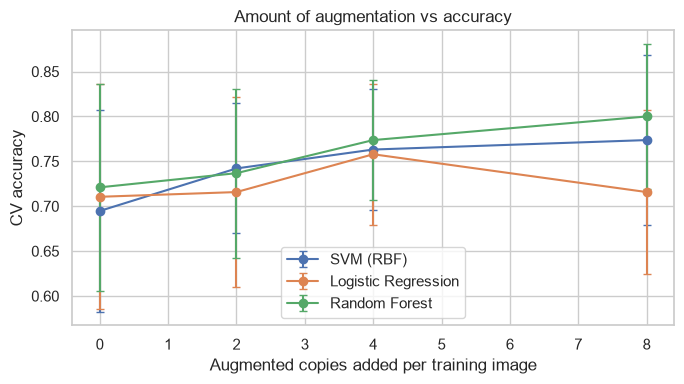

In [100]:
rows = []
for k in (0, 2, 4, 8):
    pool_k = pool_combo[:, :k] if k > 0 else None
    for mname, mdl in exp_models.items():
        acc, _ = cv_evaluate(mdl, X_train, y_train, aug=pool_k)
        rows.append({"Copies per image": k, "Model": mname, "mean": acc.mean(), "std": acc.std()})
augB = pd.DataFrame(rows)
tabB = augB.pivot(index="Copies per image", columns="Model", values="mean")
display(tabB.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for mname in exp_models:
    s = augB[augB["Model"] == mname]
    ax.errorbar(s["Copies per image"], s["mean"], yerr=s["std"], marker="o", capsize=3, label=mname)
ax.set_xlabel("Augmented copies added per training image"); ax.set_ylabel("CV accuracy")
ax.set_title("Amount of augmentation vs accuracy"); ax.legend(); plt.tight_layout(); plt.show()

Setting,Geometric x8,No augmentation
Train fraction,,
0.25,0.6000,0.5421
0.50,0.6579,0.6158
0.75,0.7526,0.6789
1.00,0.7579,0.6947


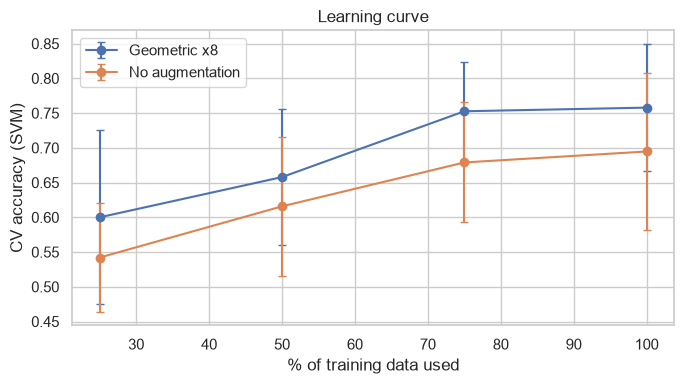

In [101]:
rows = []
svm_t = tuned["SVM (RBF)"]
for frac in (0.25, 0.5, 0.75, 1.0):
    for label, pool in (("No augmentation", None), (best_aug_name, best_pool)):
        acc, _ = cv_evaluate(svm_t, X_train, y_train, aug=pool, train_frac=frac)
        rows.append({"Train fraction": frac, "Setting": label, "mean": acc.mean(), "std": acc.std()})
lc = pd.DataFrame(rows).drop_duplicates(["Train fraction", "Setting"])
display(lc.pivot(index="Train fraction", columns="Setting", values="mean").round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for label, s in lc.groupby("Setting"):
    ax.errorbar(s["Train fraction"] * 100, s["mean"], yerr=s["std"], marker="o", capsize=3, label=label)
ax.set_xlabel("% of training data used"); ax.set_ylabel("CV accuracy (SVM)")
ax.set_title("Learning curve"); ax.legend(); plt.tight_layout(); plt.show()

Masked features computed in 2 s | average share of pixels treated as background: 50.6 %


Features,Background removed,Full image
Model,,
Random Forest,0.7632,0.7211
SVM (RBF),0.7526,0.6947


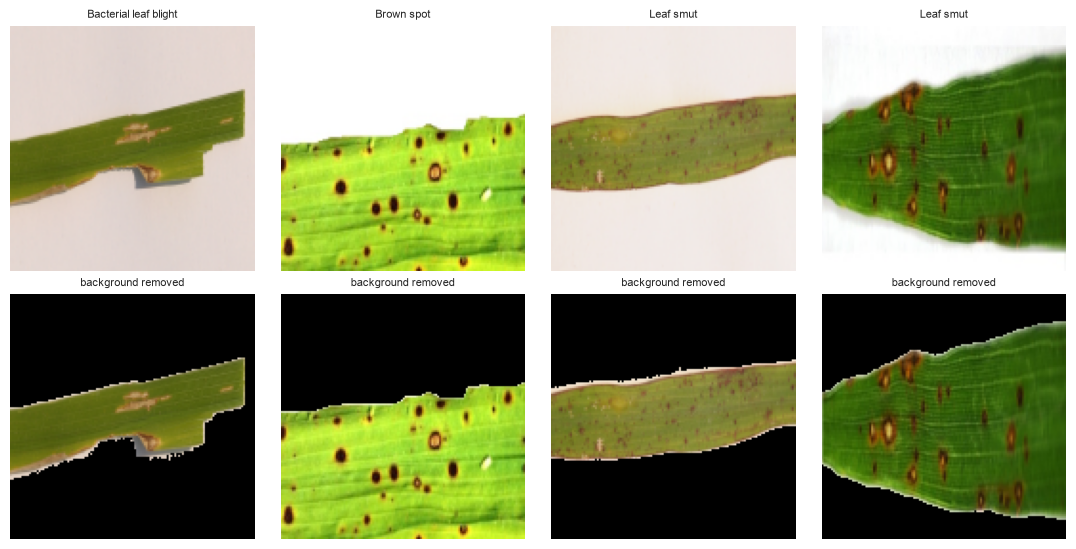

In [102]:
t0 = time.time()
X_all_mask = np.array([extract_features(im, mask_bg=True) for im in images])
X_train_mask = X_all_mask[idx_train]
print(f"Masked features computed in {time.time() - t0:.0f} s | average share of pixels treated as background: "
      f"{100 * np.mean([1 - background_mask(im).mean() for im in images]):.1f} %")

rows = []
for mname in ("SVM (RBF)", "Random Forest"):
    for label, Xc in (("Full image", X_train), ("Background removed", X_train_mask)):
        acc, _ = cv_evaluate(tuned[mname], Xc, y_train)
        rows.append({"Model": mname, "Features": label, "mean": acc.mean(), "std": acc.std()})
maskdf = pd.DataFrame(rows)
display(maskdf.pivot(index="Model", columns="Features", values="mean").round(4))

# show what the mask does
fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for a, i in zip(axes.T, [0, 45, 85, 110]):
    a[0].imshow(images[i]); a[0].set_title(class_names[y[i]], fontsize=8)
    a[1].imshow(images[i] * background_mask(images[i])[..., None]); a[1].set_title("background removed", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
group_sets = {
    "Colour stats only":      ["color_stats"],
    "HSV histogram only":     ["hsv_hist"],
    "Colour (stats + hist)":  ["color_stats", "hsv_hist"],
    "LBP only":               ["lbp"],
    "GLCM only":              ["glcm"],
    "Texture (LBP + GLCM)":   ["lbp", "glcm"],
    "HOG only":               ["hog"],
    "All except HOG":         ["color_stats", "hsv_hist", "lbp", "glcm"],
    "All features":           list(GROUP_SLICES),
}
rows = []
for gname, groups in group_sets.items():
    cols = np.concatenate([GROUP_SLICES[g] for g in groups])
    for mname in ("SVM (RBF)", "Random Forest"):
        acc, _ = cv_evaluate(tuned[mname], X_train, y_train, cols=cols)
        rows.append({"Feature set": gname, "# features": len(cols), "Model": mname, "mean": acc.mean(), "std": acc.std()})
ablate = pd.DataFrame(rows)
tabE = ablate.pivot_table(index=["Feature set", "# features"], columns="Model", values="mean", sort=False)
display(tabE.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
sub = ablate[ablate["Model"] == "SVM (RBF)"]
ax.barh(sub["Feature set"][::-1], sub["mean"][::-1], xerr=sub["std"][::-1], color="#5b8def", capsize=3)
ax.set_xlabel("CV accuracy (SVM)"); ax.set_xlim(0, 1.05); ax.set_title("Accuracy by feature group")
plt.tight_layout(); plt.show()

In [ ]:
svc_template = clone(tuned["SVM (RBF)"].named_steps["clf"])
prep_variants = {
    "No scaling":              Pipeline([("clf", clone(svc_template))]),
    "StandardScaler":          Pipeline([("sc", StandardScaler()), ("clf", clone(svc_template))]),
    "StandardScaler + PCA95":  Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=0.95, random_state=SEED)),
                                         ("clf", clone(svc_template))]),
}
rows = []
for name, mdl in prep_variants.items():
    acc, f1 = cv_evaluate(mdl, X_train, y_train)
    rows.append({"Preprocessing": name, "CV accuracy": acc.mean(), "± std": acc.std(), "CV macro-F1": f1.mean()})
display(pd.DataFrame(rows).round(4))
n_pca = PCA(n_components=0.95, random_state=SEED).fit(StandardScaler().fit_transform(X_train)).n_components_
print(f"PCA keeping 95 % variance reduces {X_train.shape[1]} features to {n_pca} components.")

In [ ]:
def fit_with_aug(model, X_tr, y_tr, pool):
    if pool is None:
        return clone(model).fit(X_tr, y_tr)
    k = pool.shape[1]
    Xa = np.vstack([X_tr, pool.reshape(-1, pool.shape[-1])])
    ya = np.concatenate([y_tr, np.repeat(y_tr, k)])
    return clone(model).fit(Xa, ya)

rows = []
for label, pool in (("No augmentation", None), (best_aug_name, best_pool)):
    m = fit_with_aug(final_models[best_name], X_train, y_train, pool)
    p = m.predict(X_test)
    rows.append({"Setting": label, "Test accuracy": accuracy_score(y_test, p),
                 "Test macro-F1": f1_score(y_test, p, average="macro"),
                 "Training samples": len(y_train) * (1 + (0 if pool is None else pool.shape[1]))})
display(pd.DataFrame(rows).drop_duplicates("Setting").round(4))
print("Reminder: the test set has only", len(y_test), "images, so one image = ", round(100 / len(y_test), 1), "percentage points.")

In [ ]:
def best_row(df, col="mean"):
    return df.loc[df[col].idxmax()]

print("TASK 3 REPORT - TECHNIQUE ANALYSIS")
print("=" * 70)

print("\n1) Data augmentation (Experiment A)")
for aname in AUG_CONFIGS:
    print(f"   - {aname:<18}: average CV accuracy over 3 models = {avg_by_aug[aname]:.3f}")
delta = avg_by_aug[best_aug_name] - base_avg
if best_aug_name == "No augmentation":
    print("   => None of the augmentation families beat the un-augmented baseline on average.")
    print("      A possible reason: flips/rotations barely change the colour statistics the models rely on,")
    print("      so augmentation adds little new information for these hand-crafted features.")
else:
    print(f"   => '{best_aug_name}' is best: {100*delta:+.1f} percentage points vs. no augmentation.")

print("\n2) Amount of augmentation (Experiment B)")
bk = tabB.mean(axis=1)
print("   Average accuracy by copies per image:", {int(k): round(v, 3) for k, v in bk.items()})
print(f"   => Best amount: {int(bk.idxmax())} copies per image.")

print("\n3) Learning curve (Experiment C)")
piv = lc.pivot(index="Train fraction", columns="Setting", values="mean")
if best_aug_name != "No augmentation":
    gap = (piv[best_aug_name] - piv["No augmentation"]) * 100
    print("   Augmentation gain (pp) by training fraction:", {f"{int(k*100)}%": round(v, 1) for k, v in gap.items()})
print("   Accuracy without augmentation by training fraction:",
      {f"{int(k*100)}%": round(v, 3) for k, v in piv["No augmentation"].items()})

print("\n4) Background removal (Experiment D)")
mp = maskdf.pivot(index="Model", columns="Features", values="mean")
for mname, r in mp.iterrows():
    print(f"   - {mname}: full image {r['Full image']:.3f} vs background removed {r['Background removed']:.3f}")

print("\n5) Feature groups (Experiment E)")
single = ablate[(ablate["Model"] == "SVM (RBF)") & ablate["Feature set"].str.contains("only")]
top_single = best_row(single)
print(f"   - Best single group for the SVM: {top_single['Feature set']} ({top_single['mean']:.3f})")
allf = ablate[(ablate['Model'] == 'SVM (RBF)') & (ablate['Feature set'] == 'All features')]['mean'].iloc[0]
print(f"   - All features together       : {allf:.3f}")

print("\n6) Scaling / PCA (Experiment F)")
print("   See the table in section 3.10 (scaling and PCA comparison for the SVM).")
print("\n(Remember: with 96 training images every CV estimate has a standard deviation of a few percentage")
print(" points - differences smaller than one standard deviation should not be over-interpreted.)")

In [95]:
rows, fitted = [], {}
for name, mdl in final_models.items():
    acc, f1 = cv_evaluate(mdl, X_train, y_train, aug=best_pool, seed=SEED + 2)
    t0 = time.time(); m = fit_with_aug(mdl, X_train, y_train, best_pool); fit_t = time.time() - t0
    t0 = time.time(); p = m.predict(X_test); pred_ms = 1000 * (time.time() - t0) / len(X_test)
    fitted[name] = m
    rows.append({"Model": name,
                 "CV acc": acc.mean(), "CV std": acc.std(), "CV macro-F1": f1.mean(),
                 "Test acc": accuracy_score(y_test, p), "Test macro-F1": f1_score(y_test, p, average="macro"),
                 "Fit time (s)": fit_t, "Predict (ms/img, model only)": pred_ms,
                 "Model size (KB)": len(pickle.dumps(m)) / 1024})
comp = pd.DataFrame(rows).sort_values(["CV acc", "Test acc"], ascending=False).reset_index(drop=True)
comp.index = comp.index + 1
display(comp.round(4))

,Model,CV acc,CV std,CV macro-F1,Test acc,Test macro-F1,Fit time (s),"Predict (ms/img, model only)",Model size (KB)
1,MLP (Neural Net),0.8737,0.0632,0.8721,0.8333,0.8320,2.2473,0.0840,1642.6035
2,Extra Trees,0.8632,0.0586,0.8600,0.8750,0.8745,1.2979,3.5514,9188.4814
3,Random Forest,0.8526,0.0698,0.8502,0.8750,0.8745,1.9543,4.0305,6120.0762
4,Gradient Boosting,0.8211,0.0918,0.8184,0.8750,0.8745,30.6556,0.3135,1446.2637
5,SVM (RBF),0.8211,0.0752,0.8163,0.8333,0.8331,0.1954,0.3531,2020.9424
6,SVM (Linear),0.7947,0.0724,0.7901,0.8333,0.8331,0.1060,0.0838,1003.3818
7,Logistic Regression,0.7895,0.0781,0.7851,0.8333,0.8356,0.1229,0.0000,19.9219
8,KNN,0.7684,0.1004,0.7601,0.8333,0.8331,0.0221,0.1674,2702.3818
9,Gaussian Naive Bayes,0.6053,0.0978,0.5879,0.7083,0.7027,0.0248,0.1673,29.2217


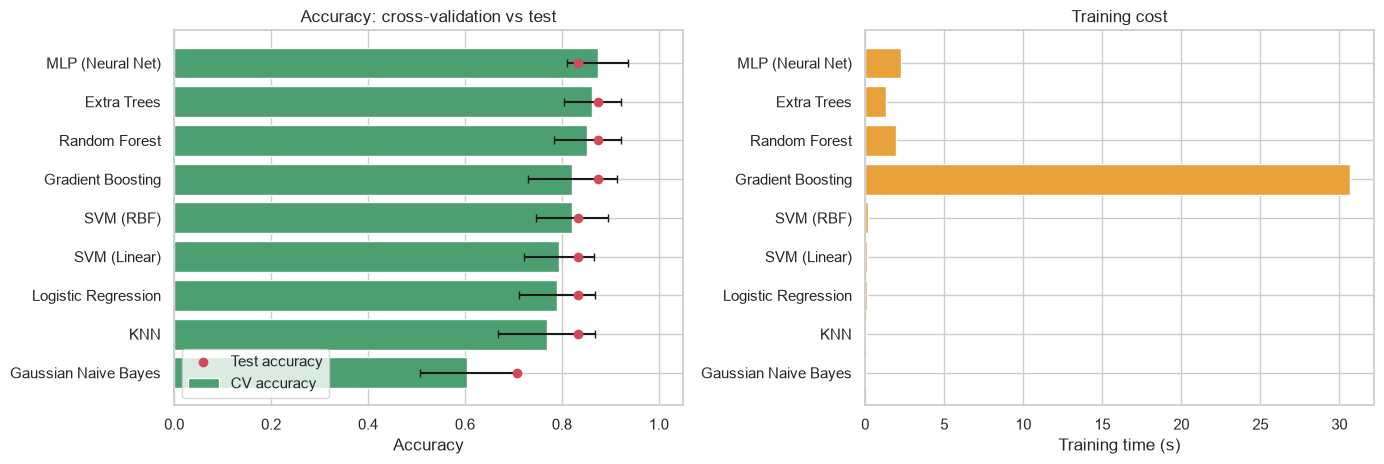

In [114]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
order = comp["Model"][::-1]
axes[0].barh(order, comp["CV acc"][::-1], xerr=comp["CV std"][::-1], color="#4c9f70", capsize=3, label="CV accuracy")
axes[0].scatter(comp["Test acc"][::-1], np.arange(len(comp)), color="#d1495b", zorder=3, label="Test accuracy")
axes[0].set_xlim(0, 1.05); axes[0].set_xlabel("Accuracy"); axes[0].set_title("Accuracy: cross-validation vs test"); axes[0].legend(loc="lower left")
axes[1].barh(order, comp["Fit time (s)"][::-1], color="#e9a23b")
axes[1].set_xlabel("Training time (s)"); axes[1].set_title("Training cost")
plt.tight_layout(); plt.show()

In [115]:
top = comp.iloc[0]
tol = max(0.02, top["CV std"])
eligible = comp[comp["CV acc"] >= top["CV acc"] - tol].copy()
eligible["cost_rank"] = eligible["Predict (ms/img, model only)"].rank() + eligible["Model size (KB)"].rank()
rec = eligible.sort_values(["cost_rank", "CV acc"], ascending=[True, False]).iloc[0]
latency_total = FEATURE_MS + rec["Predict (ms/img, model only)"]

print("MODEL COMPARISON - SUMMARY")
print("-" * 70)
print(f"Highest CV accuracy : {top['Model']}  (CV {top['CV acc']:.3f} ± {top['CV std']:.3f}, test {top['Test acc']:.3f})")
print(f"Models within tolerance ({tol:.3f}) of the best: {', '.join(eligible['Model'])}")
print(f"\nRECOMMENDED FOR PRODUCTION: {rec['Model']}")
print(f"  - CV accuracy {rec['CV acc']:.3f} ± {rec['CV std']:.3f} | test accuracy {rec['Test acc']:.3f} | test macro-F1 {rec['Test macro-F1']:.3f}")
print(f"  - model size {rec['Model size (KB)']:.0f} KB | end-to-end latency ≈ {latency_total:.1f} ms per image "
      f"({FEATURE_MS:.1f} ms feature extraction + {rec['Predict (ms/img, model only)']:.2f} ms model)")
print(f"  - trained with: {best_aug_name}")
print("\nCaveats: the test set holds only", len(y_test), "images; validate on new field photos before deployment.")

MODEL COMPARISON - SUMMARY
----------------------------------------------------------------------
Highest CV accuracy : MLP (Neural Net)  (CV 0.874 ± 0.063, test 0.833)
Models within tolerance (0.063) of the best: MLP (Neural Net), Extra Trees, Random Forest, Gradient Boosting, SVM (RBF)

RECOMMENDED FOR PRODUCTION: MLP (Neural Net)
  - CV accuracy 0.874 ± 0.063 | test accuracy 0.833 | test macro-F1 0.832
  - model size 1643 KB | end-to-end latency ≈ 20.4 ms per image (20.3 ms feature extraction + 0.08 ms model)
  - trained with: Geometric x8

Caveats: the test set holds only 24 images; validate on new field photos before deployment.


In [116]:
prod_model = fitted[rec["Model"]]
joblib.dump({"model": prod_model, "classes": class_names, "img_size": IMG_SIZE}, "rice_leaf_model.joblib")
print("Saved rice_leaf_model.joblib:", round(os.path.getsize("rice_leaf_model.joblib") / 1024, 1), "KB")

def predict_leaf_disease(image_path, bundle_path="rice_leaf_model.joblib"):
    bundle = joblib.load(bundle_path)
    bgr = cv2.imread(str(image_path))
    if bgr is None:
        raise ValueError(f"Cannot read image: {image_path}")
    rgb = cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), (bundle["img_size"],) * 2, interpolation=cv2.INTER_AREA)
    pred = bundle["model"].predict(extract_features(rgb).reshape(1, -1))[0]
    return bundle["classes"][pred]

demo_i = idx_test[0]
print("Image     :", image_paths[demo_i].name)
print("True class:", class_names[y[demo_i]])
print("Predicted :", predict_leaf_disease(image_paths[demo_i]))

Saved rice_leaf_model.joblib: 1643.4 KB
Image     : DSC_0330.jpg
True class: Leaf smut
Predicted : Brown spot


In [117]:
print("CHALLENGES - NUMBERS FROM THIS RUN")
print("-" * 70)
print(f"1) Dataset size        : {len(images)} images total, {len(idx_train)} used for training, {len(idx_test)} for testing")
print(f"2) Evaluation noise    : CV std of the selected model = {select_df.iloc[0]['± std']:.3f}; "
      f"one test image = {100/len(y_test):.1f} percentage points")
print(f"3) Dimensionality      : {X_all.shape[1]} features for {len(idx_train)} training images; "
      f"PCA(95% variance) needs {n_pca} components")
print(f"4) Original image sizes: min {np.min(orig_shapes, axis=0).tolist()}, max {np.max(orig_shapes, axis=0).tolist()} (H, W) -> all resized to {IMG_SIZE}x{IMG_SIZE}")
print(f"5) Augmentation result : best setting '{best_aug_name}' "
      f"({100*(avg_by_aug[best_aug_name]-base_avg):+.1f} pp vs none, averaged over 3 models)")
print(f"6) Final model         : {rec['Model']} - test accuracy {rec['Test acc']:.3f}")

CHALLENGES - NUMBERS FROM THIS RUN
----------------------------------------------------------------------
1) Dataset size        : 119 images total, 95 used for training, 24 for testing
2) Evaluation noise    : CV std of the selected model = 0.089; one test image = 4.2 percentage points
3) Dimensionality      : 402 features for 95 training images; PCA(95% variance) needs 47 components
4) Original image sizes: min [71, 250], max [900, 3081] (H, W) -> all resized to 128x128
5) Augmentation result : best setting 'Geometric x8' (+6.8 pp vs none, averaged over 3 models)
6) Final model         : MLP (Neural Net) - test accuracy 0.833
